In [1]:
# %pip install panel

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [3]:
data = pd.read_csv("./datasets/occupancy.csv")

In [4]:
data.head()

,date,Temperature,Humidity,Light,CO2,HumidityRatio,Occupancy
1,2015-02-11 14:48:00,21.7600,31.133333,437.333333,1029.666667,0.005021,1
2,2015-02-11 14:49:00,21.7900,31.000000,437.333333,1000.000000,0.005009,1
3,2015-02-11 14:50:00,21.7675,31.122500,434.000000,1003.750000,0.005022,1
4,2015-02-11 14:51:00,21.7675,31.122500,439.000000,1009.500000,0.005022,1
5,2015-02-11 14:51:59,21.7900,31.133333,437.333333,1005.666667,0.005030,1


In [5]:
data.info()

<class 'pandas.core.frame.DataFrame'>
Index: 9752 entries, 1 to 9752
Data columns (total 7 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   date           9752 non-null   object 
 1   Temperature    9752 non-null   float64
 2   Humidity       9752 non-null   float64
 3   Light          9752 non-null   float64
 4   CO2            9752 non-null   float64
 5   HumidityRatio  9752 non-null   float64
 6   Occupancy      9752 non-null   int64  
dtypes: float64(5), int64(1), object(1)
memory usage: 609.5+ KB


In [6]:
data["date"] = data.date.astype("datetime64[ns]")

In [7]:
from matplotlib.figure import Figure
from matplotlib.backends.backend_agg import FigureCanvas

%matplotlib inline

def mpl_plot(avg, highlight):
    fig = Figure()
    FigureCanvas(fig) # not needed in mpl >= 3.1
    ax = fig.add_subplot()
    avg.plot(ax=ax)
    if len(highlight): highlight.plot(style='o', ax=ax)
    return fig

def find_outliers(variable='Temperature', window=30, sigma=10, view_fn=mpl_plot):
    avg = data[variable].rolling(window=window).mean()
    residual = data[variable] - avg
    std = residual.rolling(window=window).std()
    outliers = (np.abs(residual) > std * sigma)
    return view_fn(avg, avg[outliers])

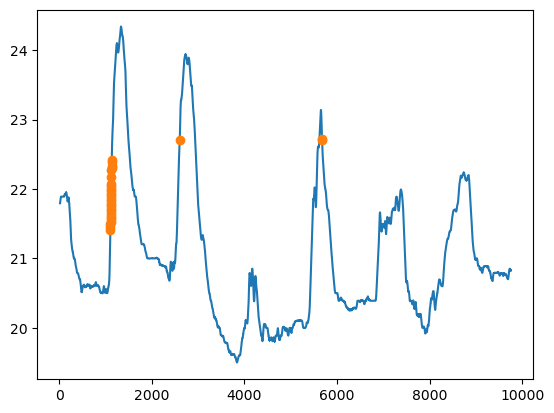

In [8]:
find_outliers(variable="Temperature", window=20, sigma=10)

In [9]:
import panel as pn
pn.extension()

In [10]:
pn.interact(find_outliers)

BokehModel(combine_events=True, render_bundle={'docs_json': {'2382828f-1daf-46b9-9bdf-02e4d28e4b03': {'version…

In [11]:
# %pip install jupyter_bokeh

In [14]:
kw = dict(window=(1,60), variable=sorted(list(data.columns)), sigma=(1,20))
# window=(1,60) hour
print(kw)


{'window': (1, 60), 'variable': ['CO2', 'Humidity', 'HumidityRatio', 'Light', 'Occupancy', 'Temperature', 'date'], 'sigma': (1, 20)}


In [16]:
i = pn.interact(find_outliers, **kw)

In [22]:
print(i)

Column
    [0] Column
        [0] Select(name='variable', options=['CO2', 'Humidity', ...], value='Temperature')
        [1] IntSlider(end=60, name='window', start=1, value=30)
        [2] IntSlider(end=20, name='sigma', start=1, value=10)
    [1] Row
        [0] Matplotlib(Figure, name='interactive00233')


In [26]:
text = "Room Occupancy"

p = pn.Row(i[1][0], pn.Column(text,i[0][0],i[0][2]))
p

BokehModel(combine_events=True, render_bundle={'docs_json': {'13c72bf4-1a23-40e8-b4ae-c3911d650bba': {'version…

In [27]:
text = "## Room Occupancy"

p=pn.Row(pn.Column(text,i[0][0],i[0][2],i[0][1]),i[1][0] )

p

BokehModel(combine_events=True, render_bundle={'docs_json': {'e395e97d-0438-49df-9123-d11fc4553a28': {'version…

In [ ]:
# %pip install hvplot

In [30]:
# %pip install holoviews

In [32]:
import hvplot.pandas

def hvplot(avg, highlight):
  return avg.hvplot(height=200) * highlight.hvplot.scatter(color='orange', padding=0.1)
 
text2 = "## Room Occupancy\nSelect the variable and the smoothing values"
hvp   = pn.interact(find_outliers, view_fn=hvplot, **kw)
pn.Column(pn.Row(pn.panel(text2, width=400), hvp[0]), hvp[1]).servable("Occupancy")

BokehModel(combine_events=True, render_bundle={'docs_json': {'9b671992-7bba-43a8-ad2a-b4cc08c92514': {'version…

In [36]:
import holoviews as hv

tap = hv.streams.PointerX(x=data.index.min())

def hvplot2(avg, highlight):
  line = avg.hvplot(height=300, width=500)
  outliers = highlight.hvplot.scatter(color="orange", padding=0.1)
  tap.source = line
  return (line * outliers).opts(legend_position="top_right")

@pn.depends(tap.param.x)
def table(x):
  index = np.abs((data.index - x).astype(int)).argmin()
  return data.iloc[index]

app = pn.interact(find_outliers, view_fn=hvplot2, **kw)

pn.Row(
  pn.Column("## Room Occupancy\nHover over the plot for more information.", app[0]),
  pn.Row(app[1], table),
)

BokehModel(combine_events=True, render_bundle={'docs_json': {'fc4051ee-eb3b-436b-8e61-b27f98283954': {'version…

UnknownReferenceError: can't resolve reference '0e2c9205-1a48-470f-ba67-17f02eba6733'

UnknownReferenceError: can't resolve reference '0e2c9205-1a48-470f-ba67-17f02eba6733'

UnknownReferenceError: can't resolve reference '0e2c9205-1a48-470f-ba67-17f02eba6733'

UnknownReferenceError: can't resolve reference '0e2c9205-1a48-470f-ba67-17f02eba6733'